# 1.1 Statically determinate beams

A beam is **statically determinate** when the three equations of plane equilibrium give every reaction: ΣH = 0, ΣV = 0, ΣM = 0.
Internal forces follow by cutting the beam and applying equilibrium to one side.

*Textbook topic:* Hibbeler, *Structural Analysis*: internal loadings, shear and moment diagrams.

In [1]:
import sys; sys.path.insert(0, '..')
from ec2.setup import *

## Relations used in every example

$$\frac{dV}{dx} = -w(x), \qquad \frac{dM}{dx} = V(x)$$

The bending moment is a maximum (or minimum) where the shear is zero or changes sign.

| Case | Maximum moment | Maximum shear |
|:--|:-:|:-:|
| Simply supported, UDL w | wL²/8 | wL/2 |
| Simply supported, central P | PL/4 | P/2 |
| Simply supported, P at a, b | Pab/L | P·max(a, b)/L |
| Simply supported, triangular 0 to w | wL²/(9√3) | wL/3 |
| Cantilever, UDL w | −wL²/2 | wL |
| Cantilever, end load P | −PL | P |

## Example 1: simply supported beam, UDL + point load

### Input guide

| Name | Meaning | Unit | Expected |
|:--|:--|:--|:--|
| `L` | Span | m | > 0 |
| `w` | Uniform load | kN/m | any |
| `P` | Point load | kN | any |
| `a` | Distance of P from A | m | 0 to L |

Keep the order inside `dict(...)`. A changed order gives wrong answers without an error.

In [2]:
# INPUTS: edit only this cell, then run the cells below it
ex1 = dict(L=7.0, w=20.0, P=30.0, a=2.0)      # m, kN/m, kN, m (P at a from A)

## Simply supported beam

*Project:* EC2 design guide &nbsp;|&nbsp; *Element:* Example 1

### Equilibrium

| Reference | Calculation | Output |
|:--|:--|:--|
|  | Span: $L$ | $L = 7$ m |
|  | UDL: $w$ | $w = 20$ kN/m |
|  | Point load: $P$ | $P = 30$ kN |
|  | Distance of P from A: $a$ | $a = 2$ m |
| ΣM about A = 0 | $R_{B} = \dfrac{\dfrac{w\,L^{2}}{2} + P\,a}{L}$<br>$\quad = \dfrac{\dfrac{20\times 7^{2}}{2} + 30\times 2}{7}$ | $\mathbf{R_{B} = 78.57}$ kN |
| ΣV = 0 | $R_{A} = w\,L + P - R_{B}$<br>$\quad = 20\times 7 + 30 - 78.57$ | $\mathbf{R_{A} = 91.43}$ kN |
| Section just left of P | $V_{a,left} = R_{A} - w\,a$<br>$\quad = 91.43 - 20\times 2$ | $\mathbf{V_{a,left} = 51.43}$ kN |
| Section just right of P | $V_{a,right} = V_{a,left} - P$<br>$\quad = 51.43 - 30$ | $\mathbf{V_{a,right} = 21.43}$ kN |
| V = 0 to the right of P | $x_{0} = \dfrac{R_{A} - P}{w}$<br>$\quad = \dfrac{91.43 - 30}{20}$ | $\mathbf{x_{0} = 3.071}$ m |
| M at V = 0 | $M_{max} = R_{A}\,x_{0} - \dfrac{w\,x_{0}^{2}}{2} - P\,\max\left\{x_{0} - a;\; 0\right\}$<br>$\quad = 91.43\times 3.071 - \dfrac{20\times 3.071^{2}}{2} - 30\times \max\left\{3.071 - 2;\; 0\right\}$ | $\mathbf{M_{max} = 154.3}$ kN·m |
|  | Program value: $M_{prog}$ | $M_{prog} = 154.3$ kN·m |
|  | **Check:** hand formula = program | ✅ **PASS** |


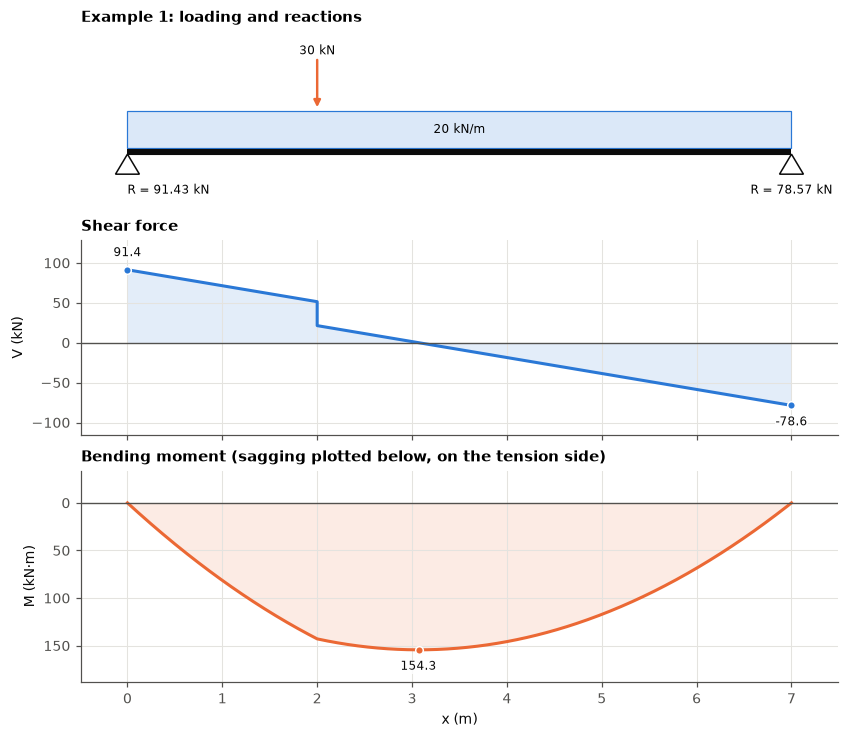

In [3]:
L, w, Pl, a = ex1.values()

s = Sheet("Simply supported beam", element="Example 1")
s.let("L", L, "m", "Span"); s.let("w", w, "kN/m", "UDL"); s.let("P", Pl, "kN", "Point load"); s.let("a", a, "m", "Distance of P from A")
s.calc("R_B", "(w*L**2/2 + P*a)/L", "kN", "ΣM about A = 0")
s.calc("R_A", "w*L + P - R_B", "kN", "ΣV = 0")
s.calc("V_a_left", "R_A - w*a", "kN", "Section just left of P")
s.calc("V_a_right", "V_a_left - P", "kN", "Section just right of P")
if s["V_a_right"] <= 0 <= s["V_a_left"]:
    s.let("x_0", a, "m", "Shear changes sign at the point load", "V = 0")
elif s["V_a_left"] < 0:
    s.calc("x_0", "R_A/w", "m", "V = 0")
else:
    s.calc("x_0", "(R_A - P)/w", "m", "V = 0 to the right of P")
s.calc("M_max", "R_A*x_0 - w*x_0**2/2 - P*max(x_0 - a, 0)", "kN·m", "M at V = 0")
bm = DeterminateBeam(L, [UDL(w), Point(Pl, a)], supports=(0, L))
s.let("M_prog", bm.M.max(), "kN·m", "Program value")
s.verdict(abs(bm.M.max() - s["M_max"]) < 0.05, "hand formula = program")
s.show("Equilibrium")
P.determinate(bm, "Example 1: loading and reactions")

## Example 2: cantilever with UDL + end load

### Input guide

| Name | Meaning | Unit | Expected |
|:--|:--|:--|:--|
| `L` | Cantilever length | m | > 0 |
| `w` | Uniform load | kN/m | any |
| `P` | Load at the free end | kN | any |

Keep the order inside `dict(...)`.

In [4]:
# INPUTS: edit only this cell, then run the cells below it
ex2 = dict(L=2.0, w=8.0, P=10.0)      # m, kN/m, kN (P at the free end)

## Cantilever

*Project:* EC2 design guide &nbsp;|&nbsp; *Element:* Example 2

### Equilibrium

| Reference | Calculation | Output |
|:--|:--|:--|
|  | $L$ | $L = 2$ m |
|  | $w$ | $w = 8$ kN/m |
|  | Load at the free end: $P$ | $P = 10$ kN |
| ΣV = 0 | $V_{fix} = w\,L + P$<br>$\quad = 8\times 2 + 10$ | $\mathbf{V_{fix} = 26}$ kN |
| ΣM at the fixed end | $M_{fix} = -\left(\dfrac{w\,L^{2}}{2} + P\,L\right)$<br>$\quad = -\left(\dfrac{8\times 2^{2}}{2} + 10\times 2\right)$ | $\mathbf{M_{fix} = -36}$ kN·m |
|  | **Check:** hand formula = program | ✅ **PASS** |


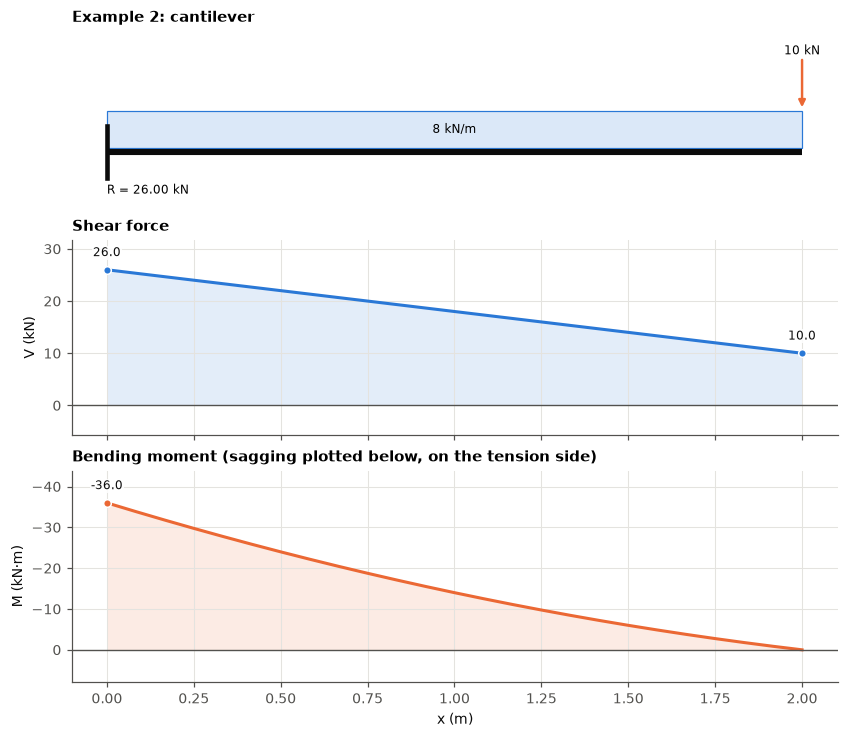

In [5]:
L, w, Pl = ex2.values()

s = Sheet("Cantilever", element="Example 2")
s.let("L", L, "m"); s.let("w", w, "kN/m"); s.let("P", Pl, "kN", "Load at the free end")
s.calc("V_fix", "w*L + P", "kN", "ΣV = 0")
s.calc("M_fix", "-(w*L**2/2 + P*L)", "kN·m", "ΣM at the fixed end")
bm = DeterminateBeam(L, [UDL(w), Point(Pl, L)], fixed="left")
s.verdict(abs(bm.MA - s["M_fix"]) < 1e-6, "hand formula = program")
s.show("Equilibrium")
P.determinate(bm, "Example 2: cantilever")

## Example 3: overhanging beam

### Input guide

| Name | Meaning | Unit | Expected |
|:--|:--|:--|:--|
| `L1` | Distance between supports | m | > 0 |
| `c` | Overhang beyond B | m | ≥ 0 |
| `w` | Uniform load on the whole beam | kN/m | any |

Keep the order inside `dict(...)`.

In [6]:
# INPUTS: edit only this cell, then run the cells below it
ex3 = dict(L1=6.0, c=2.0, w=10.0)      # m, m, kN/m (span, overhang, UDL on everything)

## Overhanging beam

*Project:* EC2 design guide &nbsp;|&nbsp; *Element:* Example 3

### Equilibrium

| Reference | Calculation | Output |
|:--|:--|:--|
|  | Span A to B: $L_{1}$ | $L_{1} = 6$ m |
|  | Overhang beyond B: $c$ | $c = 2$ m |
|  | $w$ | $w = 10$ kN/m |
| ΣM about A = 0 | $R_{B} = \dfrac{\dfrac{w\,\left(L_{1} + c\right)^{2}}{2}}{L_{1}}$<br>$\quad = \dfrac{\dfrac{10\times \left(6 + 2\right)^{2}}{2}}{6}$ | $\mathbf{R_{B} = 53.33}$ kN |
| ΣV = 0 | $R_{A} = w\,\left(L_{1} + c\right) - R_{B}$<br>$\quad = 10\times \left(6 + 2\right) - 53.33$ | $\mathbf{R_{A} = 26.67}$ kN |
| Overhang as a cantilever | $M_{B} = \dfrac{-w\,c^{2}}{2}$<br>$\quad = \dfrac{-10\times 2^{2}}{2}$ | $\mathbf{M_{B} = -20}$ kN·m |
| V = 0 | $x_{0} = \dfrac{R_{A}}{w}$<br>$\quad = \dfrac{26.67}{10}$ | $\mathbf{x_{0} = 2.667}$ m |
| M at V = 0 | $M_{max} = R_{A}\,x_{0} - \dfrac{w\,x_{0}^{2}}{2}$<br>$\quad = 26.67\times 2.667 - \dfrac{10\times 2.667^{2}}{2}$ | $\mathbf{M_{max} = 35.56}$ kN·m |
|  | **Check:** hand formula = program | ✅ **PASS** |


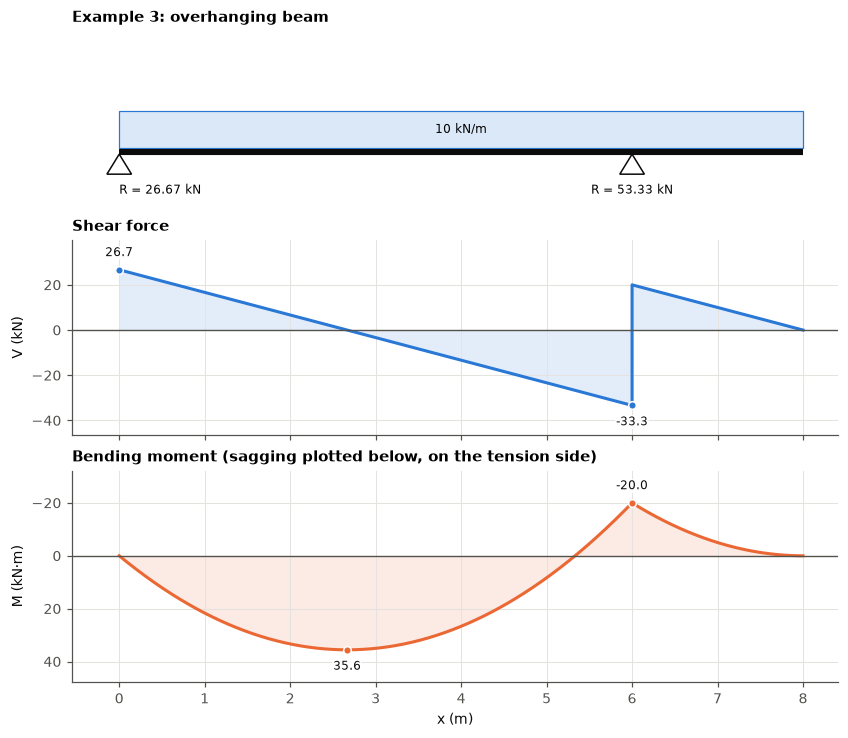

In [7]:
L1, c, w = ex3.values()

s = Sheet("Overhanging beam", element="Example 3")
s.let("L_1", L1, "m", "Span A to B"); s.let("c", c, "m", "Overhang beyond B"); s.let("w", w, "kN/m")
s.calc("R_B", "w*(L_1 + c)**2/2/L_1", "kN", "ΣM about A = 0")
s.calc("R_A", "w*(L_1 + c) - R_B", "kN", "ΣV = 0")
s.calc("M_B", "-w*c**2/2", "kN·m", "Overhang as a cantilever")
s.calc("x_0", "R_A/w", "m", "V = 0")
s.calc("M_max", "R_A*x_0 - w*x_0**2/2", "kN·m", "M at V = 0")
bm = DeterminateBeam(L1 + c, [UDL(w)], supports=(0, L1))
s.verdict(abs(bm.M.max() - s["M_max"]) < 0.02 and abs(bm.M.min() - s["M_B"]) < 0.02, "hand formula = program")
s.show("Equilibrium")
P.determinate(bm, "Example 3: overhanging beam")

## Example 4: triangular load and an applied couple

### Input guide

| Name | Meaning | Unit | Expected |
|:--|:--|:--|:--|
| `L` | Span | m | > 0 |
| `w2` | Load intensity at B (zero at A) | kN/m | > 0 |
| `M0` | Couple, clockwise positive | kN·m | any |
| `xm` | Position of the couple | m | 0 to L |

Keep the order inside `dict(...)`.

In [8]:
# INPUTS: edit only this cell, then run the cells below it
ex4 = dict(L=5.0, w2=15.0, M0=10.0, xm=3.5)      # m, kN/m, kN·m, m (couple clockwise +)

## Triangular load + couple

*Project:* EC2 design guide &nbsp;|&nbsp; *Element:* Example 4

### Equilibrium

| Reference | Calculation | Output |
|:--|:--|:--|
|  | $L$ | $L = 5$ m |
|  | Intensity at B (zero at A): $w_{2}$ | $w_{2} = 15$ kN/m |
|  | Clockwise couple: $M_{0}$ | $M_{0} = 10$ kN·m |
|  | Resultant, acting at 2L/3 from A<br>$W = \dfrac{w_{2}\,L}{2}$<br>$\quad = \dfrac{15\times 5}{2}$ | $\mathbf{W = 37.5}$ kN |
| ΣM about A = 0 | $R_{B} = \dfrac{\dfrac{W\times 2\,L}{3} + M_{0}}{L}$<br>$\quad = \dfrac{\dfrac{37.5\times 2\times 5}{3} + 10}{5}$ | $\mathbf{R_{B} = 27}$ kN |
| ΣV = 0 | $R_{A} = W - R_{B}$<br>$\quad = 37.5 - 27$ | $\mathbf{R_{A} = 10.5}$ kN |
|  | **Check:** hand formula = program | ✅ **PASS** |
|  | Maximum moment (program): $M_{max}$ | $M_{max} = 25.31$ kN·m |


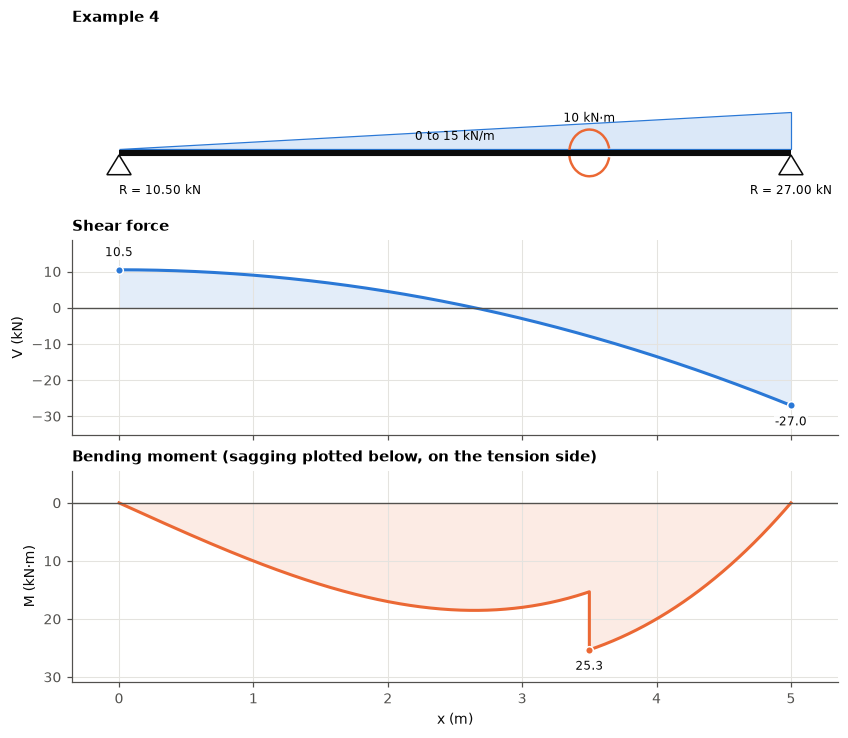

In [9]:
L, w2, M0, xm = ex4.values()

s = Sheet("Triangular load + couple", element="Example 4")
s.let("L", L, "m"); s.let("w_2", w2, "kN/m", "Intensity at B (zero at A)"); s.let("M_0", M0, "kN·m", "Clockwise couple")
s.calc("W", "w_2*L/2", "kN", "", "Resultant, acting at 2L/3 from A")
s.calc("R_B", "(W*2*L/3 + M_0)/L", "kN", "ΣM about A = 0")
s.calc("R_A", "W - R_B", "kN", "ΣV = 0")
bm = DeterminateBeam(L, [UVL(0, w2, 0, L), Moment(M0, xm)], supports=(0, L))
s.verdict(abs(bm.RA - s["R_A"]) < 1e-6, "hand formula = program")
s.let("M_max", bm.M.max(), "kN·m", "Maximum moment (program)")
s.show("Equilibrium")
P.determinate(bm, "Example 4")

**Your own beam.** Edit the list of loads: `Point(P, a)`, `UDL(w, a, b)`, `UVL(w1, w2, a, b)`, `Moment(M, a)`.

### Input guide

| Name | Meaning | Unit | Expected |
|:--|:--|:--|:--|
| `my_length` | Total length | m | > 0 |
| `my_loads` | List of loads |  | `[ ... ]`, see below |
| `my_supports` | Support positions from the left end | m | `(xA, xB)`, xA < xB |

| Write | Meaning | Units |
|:--|:--|:--|
| `Point(P, a)` | Downward load P at a | kN, m |
| `UDL(w)` or `UDL(w, a, b)` | Uniform load, whole beam or a to b | kN/m, m |
| `UVL(w1, w2, a, b)` | Load varying from w1 at a to w2 at b | kN/m, m |
| `Moment(M, a)` | Clockwise couple at a | kN·m, m |

**Not checked:** a load beyond the beam, or a larger than b, runs without an error and gives wrong answers.

In [10]:
# INPUTS: edit only this cell, then run the cells below it
my_length = 7.0                 # m
my_loads = [UDL(9.0), UDL(6.0, 1.0, 4.0), Point(25, 5.0)]      # Point(P, a), UDL(w, a, b), UVL(w1, w2, a, b), Moment(M, a)
my_supports = (0, 7.0)          # m from the left end

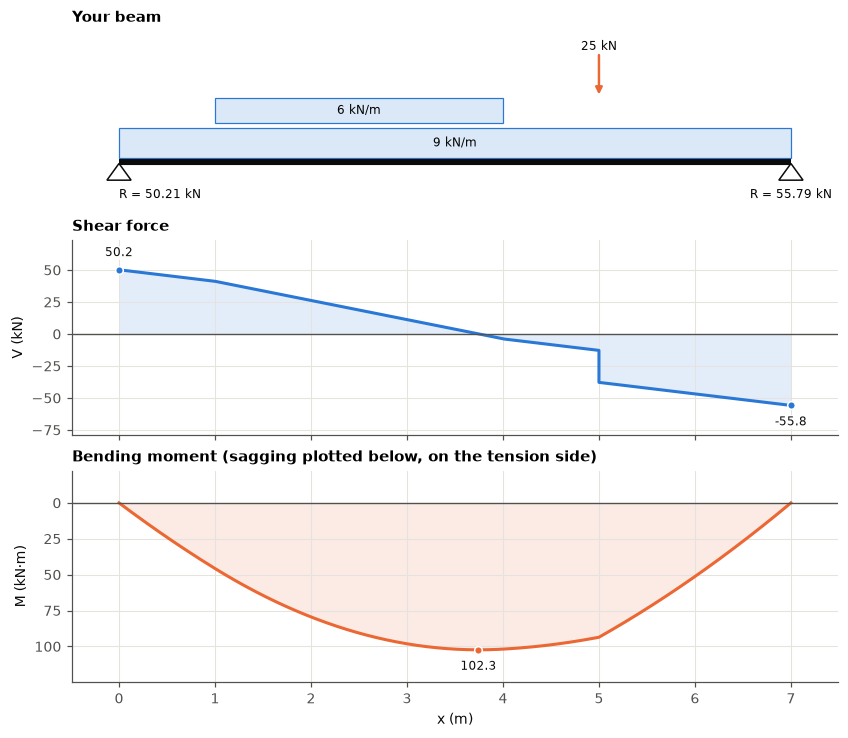

In [11]:
my = DeterminateBeam(my_length, my_loads, supports=my_supports)
P.determinate(my, "Your beam")